# Лабораторная работа 4 Исследование операций обработки изображений в Engee

**Вариант 3 — фильтр Гаусса σ=3, сцена со слабым шумом.**

Власюк Данил Витальевич, группа Т26ИИКТ-МИК11. 14 октября 2026 года.

Цель — сравнить сглаживание, повышение резкости, выделение границ, бинаризацию и морфологию относительно известного эталона. Основное исследование — вариант 3; дополнительно выполняются все шесть операций, демо, соседняя сцена и обзор 30 сочетаний. Синтетические данные: круг на градиенте, 128×128, пять seed 101–105. Обучение нейросети не требуется.

**Порядок выполнения:** поместить этот файл, `lab03_lib.jl`, `lab04_lib.jl` и `hypothesis.md` в отдельную папку `LR04` в Engee, затем выполнить все ячейки сверху вниз. Исходный ноутбук содержит код и пояснения; численные результаты и изображения формируются при фактическом запуске.

## 1 Изучение документации WorkspaceArray

Изучена [документация Engee](https://engee.com/helpcenter/stable/ru/guide/workspacearray.html), дата обращения 14.10.2026.

`WorkspaceArray` нужен для временных рядов и ленивого доступа к данным моделирования. Он поддерживает индексацию и срезы; `collect` загружает выбранные данные. Изображения этой работы представлены обычными матрицами Julia `Matrix{Float64}`: моделирование временного сигнала и `WorkspaceArray` для их обработки не требуются.

Практический пример по документации: создаём CSV с `time,value`, открываем его как `WorkspaceArray`, получаем запись и срез. Пример изолирован в функции, поэтому недоступность этого API в вычислительной сессии не прервёт обработку изображений и будет явно отражена в выводе.

# План до запуска ЛР4 вариант 3

Дата фиксации: 2026-10-14T22:26:51.046460+03:00.

Основной вариант: сцена 1, шум 0.02, операция 3 — фильтр Гаусса sigma=3. n=128, фон (0.10,0.40), диск 0.75, checker=0, seed 101…105. Эталон — clean4(1), без шума.

Гипотеза: при слабом шуме сильное сглаживание размоет границу круга сильнее, чем устранит шум, и снизит средний PSNR относительно чистой сцены. Энергия границ и контраст снизятся. Фильтр sigma=1 предположительно сохранит детали лучше sigma=3. На соседней сцене 2 с noise=0.05 ожидается более благоприятный эффект, но знак заранее не гарантирован.

Практическая классификация по разности средних PSNR: полезна при delta>=+1 дБ, вредна при delta<=-1 дБ, иначе нейтральна. Порог фиксируется до вычислений и условен. Изменение PSNR на 1 дБ соответствует изменению MSE примерно в 1.259 раза при фиксированном диапазоне. Дополнительно проверить чувствительность вывода к порогам 0.5 и 2 дБ, не меняя основной порог.

Учебный критерий: abs(delta)>2s, где s — выборочный разброс базовой метрики по seed. Это эвристика методички, а не p-значение. Результаты метрик рассчитывать по Float64 до PNG-квантования.

Все шесть операций проверить на сцене 1. Для Собеля использовать нормированную карту чистой сцены, для Оцу и открытия — истинную маску круга, дополнительно IoU. Обзор 30 сочетаний является описательным. Основная проверка гипотезы — вариант 3; сравнение — варианты 2 и 9.

In [0]:
using Images, Random, Statistics, SHA, Dates, TOML, Tar, InteractiveUtils, Printf
LR04_ROOT = isfile("lab04_lib.jl") ? pwd() : "/user/AI_in_creative_media/LR04"
cd(LR04_ROOT)
include("lab04_lib.jl")
LR04_OUT = joinpath(LR04_ROOT,"artifacts")
mkpath(LR04_OUT)
LR04_STARTED = string(now())
println("START ",LR04_STARTED,"; Julia ",VERSION,"; directory ",pwd())
versioninfo()
@assert size(make_gray4(101)) == (128,128)
@assert bytes2hex(sha256(read("lab04_lib.jl"))) == "094cecea2f55a0f53a652149a1a4025e98d87b3994b376be7028c4920cb0f8c2"
println("LIBRARIES LOADED; Images ",pkgversion(Images))

START 2026-10-14T19:38:58.968; Julia 1.12.4; directory /user/AI_in_creative_media/LR04
Julia Version 1.12.4
Commit 01a2eadb047 (2026-01-06 16:56 UTC)
Build Info:
  Official https://julialang.org release
Platform Info:
  OS: Linux (x86_64-linux-gnu)
  CPU: 112 × Intel(R) Xeon(R) Platinum 8180 CPU @ 2.50GHz
  WORD_SIZE: 64
  LLVM: libLLVM-18.1.7 (ORCJIT, skylake-avx512)
  GC: Built with stock GC
Threads: 5 default, 3 interactive, 5 GC (on 112 virtual cores)
Environment:
  JULIA_LSP_STORE_PATH = /user/lsp_store
  JULIA_CPU_TARGET = generic;sandybridge,-xsaveopt,clone_all;haswell,-rdrnd,base(1)
  JULIA_LSP_PORT = 3751
  JULIA_NUM_PRECOMPILE_TASKS = 8
  JULIA_PKG_PRECOMPILE_AUTO = 0
  JULIA_DEPOT_PATH = /user/.packages:/opt/depot/core:/opt/depot/mtl:/opt/depot/demos:/opt/depot/stdlib
  JULIA_PATH = /usr/local/julia
  LD_LIBRARY_PATH = /usr/local/nvidia/lib:/usr/local/nvidia/lib64
  JULIA_PROJECT = /user/.project/
  JULIA_DA_STORE_PATH = /user/da_store
  JULIA_PKG_SERVER = http://pkgserver.p

In [0]:
function workspacearray_demo4()
    csvpath=joinpath(LR04_OUT,"workspacearray_example.csv")
    write(csvpath,"time,value\n0.1,1\n0.2,2\n0.3,3\n0.4,4\n0.5,5\n")
    if !isdefined(Main,:WorkspaceArray)
        msg="WorkspaceArray не экспортирован в Main этой сессии. Документация изучена; для изображений используются Matrix{Float64}."
        println(msg);write(joinpath(LR04_OUT,"workspacearray_status.txt"),msg)
        return nothing
    end
    try
        wa=getfield(Main,:WorkspaceArray)("lr04_demo",csvpath)
        first_record=wa[1]
        sliced=collect(wa[1:2:end])
        println("Первая запись: ",first_record,"\nКаждая вторая запись:");display(sliced)
        write(joinpath(LR04_OUT,"workspacearray_status.txt"),"EXECUTED\n"*sprint(show,sliced))
        return wa
    catch err
        msg="Пример WorkspaceArray: "*sprint(showerror,err)
        println(msg);write(joinpath(LR04_OUT,"workspacearray_status.txt"),msg)
        return nothing
    end
end
lr04_wa=workspacearray_demo4()

Первая запись: (0.1, 1)
Каждая вторая запись:


Row,time,value
,Float64,Int64
1,0.1,1
2,0.3,3
3,0.5,5


WorkspaceArray{Int64}("lr04_demo")

## 2 Вспомогательные функции и схема измерений

PSNR вычисляется **относительно эталона своей операции**. Для фильтров эталон — чистая сцена; для Собеля — нормированная карта её границ; для масок — истинный диск. Энергия границ — средний модуль градиента Собеля, контраст — выборочное стандартное отклонение пикселей. Разброс `s` в сводке — другая величина: стандартное отклонение базовой метрики между seed. PNG нужны для просмотра, измерения выполняются до квантования на Float64.

In [0]:
SEEDS4=101:105
OPNAMES4=["Усреднение 5×5","Гаусс σ=1","Гаусс σ=3","Нерезкая маска","Собель после Гаусса","Оцу и открытие"]
class4(d,t=1.0)=d>=t ? "полезна" : d<=-t ? "вредна" : "нейтральна"
function csv4(name,headers,rows)
    open(joinpath(LR04_OUT,name),"w") do io
        println(io,join(headers,","))
        for row in rows;println(io,join(row,","));end
    end
end
function mdtable4(headers,rows)
    esc(x)=replace(string(x),"|"=>"\\|")
    "| "*join(esc.(headers)," | ")*" |\n| "*join(fill("---",length(headers))," | ")*" |\n"*
    join(["| "*join(esc.(collect(r))," | ")*" |" for r in rows],"\n")
end
function showmd4(t)
    display(MIME"text/markdown"(),t)
end
function saveimage4(name,a)
    @assert size(a)==(128,128) && all(isfinite,a) && all(v->0<=v<=1,a)
    save(joinpath(LR04_OUT,name*".png"),Gray{N0f8}.(a))
end
function savedata4(name,a)
    open(joinpath(LR04_OUT,name*".f64"),"w") do io;write(io,vec(Float64.(a)));end
end
function summarytable4(z)
    headers=["Метрика","База","s","После","Δ","Модуль Δ / s",">2s"]
    rows=[(string(m),@sprintf("%.8f",b),@sprintf("%.8f",s),@sprintf("%.8f",a),@sprintf("%+.8f",d),@sprintf("%.3f",r),sig ? "Да" : "Нет") for (m,b,s,a,d,r,sig) in z.rows]
    mdtable4(headers,rows)
end
function perseed4(c,k)
    refclean=clean4(c)
    [(seed=s,scene=c,operation=k,
      psnr_before=psnr_db(b,ref),psnr_after=psnr_db(a,ref),
      mse_before=mse(b,ref),mse_after=mse(a,ref),
      edge_before=edge_energy(b),edge_after=edge_energy(a),
      contrast_before=std(b),contrast_after=std(a),
      iou_before=k==6 ? iou(Bool.(b),Bool.(ref)) : NaN,
      iou_after=k==6 ? iou(Bool.(a),Bool.(ref)) : NaN)
     for s in SEEDS4 for (a,b,ref) in (pair4(make_gray4(s;scene4(c)...),refclean,k),)]
end
println("Схема измерений и экспорта готова")

Схема измерений и экспорта готова


## 3 Воспроизведение демонстрационного варианта

Демо из методички — усредняющий фильтр 5×5 на сцене со слабым шумом. Сопоставляем все три метрики с опубликованным журналом преподавателя. Результаты ниже получаются при запуске, а не копируются в ячейку вывода.

In [0]:
demo4=variant_summary4(1)
expected4=[(33.982103137714965,0.07450305641014086,29.19575338868147,-4.786349749033494),
(0.01692548814288977,0.00012750148456890567,0.008424262473284544,-0.008501225669605225),
(0.20774642267754806,0.00017156629178605263,0.20065402164009138,-0.007092401037456675)]
DEMO_MATCH4=all(isapprox(demo4.rows[i][j+1],expected4[i][j];atol=1e-10,rtol=0) for i in 1:3,j in 1:4)
println("MATCH_DEMO=",DEMO_MATCH4)
@assert DEMO_MATCH4
showmd4(summarytable4(demo4))

MATCH_DEMO=true


| Метрика | База | s | После | Δ | Модуль Δ / s | >2s |
| --- | --- | --- | --- | --- | --- | --- |
| psnr | 33.98210314 | 0.07450306 | 29.19575339 | -4.78634975 | 64.244 | Да |
| edge | 0.01692549 | 0.00012750 | 0.00842426 | -0.00850123 | 66.676 | Да |
| contrast | 0.20774642 | 0.00017157 | 0.20065402 | -0.00709240 | 41.339 | Да |

## 4 Исходная сцена и оценка шума

Для основного варианта фон изменяется от 0.10 до 0.40, диск имеет яркость 0.75, шум σₙ=0.02. Эталон получаем той же функцией при нулевом шуме. Сравниваем измеренный PSNR с оценкой `−20log10(σₙ)`. Повторяем построение с тем же seed и сверяем SHA-256 массива, а не файла PNG.

| Seed | Измеренный PSNR дБ | Теория дБ | Разница дБ |
| --- | --- | --- | --- |
| 101 | 33.92416352175621 | 33.979400086720375 | -0.055236564964161516 |
| 102 | 33.92048070374465 | 33.979400086720375 | -0.05891938297572352 |
| 103 | 33.981572561203635 | 33.979400086720375 | 0.0021724744832596343 |
| 104 | 34.10474776248518 | 33.979400086720375 | 0.12534767576480732 |
| 105 | 33.97955113938513 | 33.979400086720375 | 0.00015105266475501367 |

size=(128, 128); type=Float64; min/max=(0.06550155753085868, 0.8197951804301282); bytes=131072; SHA256=e7ecd4f73ea684ab746fc444eef55f0c18943d7fdcfc4fe7866b3f4b6012accf


Слева — зашумлённая сцена; справа — чистый эталон.

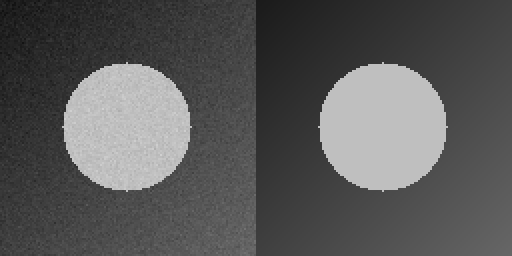

In [0]:
x4=make_gray4(101;scene4(1)...)
clean_scene4=clean4(1)
@assert x4==make_gray4(101;scene4(1)...)
@assert gauss4(x4,3)≈imfilter(x4,Kernel.gaussian(3),"replicate")
SHA_SCENE4=bytes2hex(sha256(reinterpret(UInt8,vec(x4))))
noise_rows4=[(r.seed,r.psnr_before,-20log10(scene4(1).noise),r.psnr_before+20log10(scene4(1).noise)) for r in perseed4(1,3)]
showmd4(mdtable4(["Seed","Измеренный PSNR дБ","Теория дБ","Разница дБ"],noise_rows4))
println("size=",size(x4),"; type=",eltype(x4),"; min/max=",extrema(x4),"; bytes=",sizeof(x4),"; SHA256=",SHA_SCENE4)
saveimage4("noisy_seed101",x4);saveimage4("reference_clean",clean_scene4)
savedata4("noisy_seed101",x4);savedata4("reference_clean",clean_scene4)
showmd4("Слева — зашумлённая сцена; справа — чистый эталон.")
display(Gray{N0f8}.(repeat(hcat(x4,clean_scene4),inner=(2,2))))

## 5 Все шесть операций

Каждая операция запускается на одной и той же сцене, seed 101; затем её метрики усредняются по пяти seed. Параметры определены исходной библиотекой преподавателя. Изображения показывают **базу, результат и эталон** слева направо. Для Собеля база — границы без сглаживания; для морфологии база — маска Оцу без открытия.

### Операция 1

Среднее по окну 5×5 подавляет шум и размывает резкие переходы.

**Усреднение 5×5**

| Метрика | База | s | После | Δ | Модуль Δ / s | >2s |
| --- | --- | --- | --- | --- | --- | --- |
| psnr | 33.98210314 | 0.07450306 | 29.19575339 | -4.78634975 | 64.244 | Да |
| edge | 0.01692549 | 0.00012750 | 0.00842426 | -0.00850123 | 66.676 | Да |
| contrast | 0.20774642 | 0.00017157 | 0.20065402 | -0.00709240 | 41.339 | Да |

ΔPSNR=-4.786349749033494 дБ; операция вредна


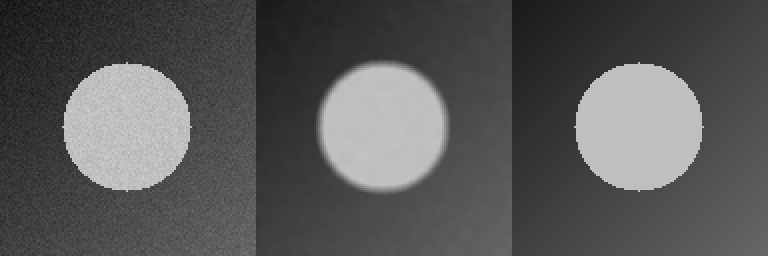

In [0]:
a4_1,b4_1,ref4_1=pair4(x4,clean_scene4,1)
z4_1=variant_summary4(1)
showmd4("**"*OPNAMES4[1]*"**\n\n"*summarytable4(z4_1))
println("ΔPSNR=",z4_1.rows[1][5]," дБ; операция ",class4(z4_1.rows[1][5]))
saveimage4("op1_result_seed101",a4_1)
saveimage4("op1_base_seed101",b4_1)
saveimage4("op1_reference",ref4_1)
display(Gray{N0f8}.(repeat(hcat(b4_1,a4_1,ref4_1),inner=(2,2))))

### Операция 2

Гаусс σ=1 использует больший вес близких пикселей и даёт мягкое сглаживание.

**Гаусс σ=1**

| Метрика | База | s | После | Δ | Модуль Δ / s | >2s |
| --- | --- | --- | --- | --- | --- | --- |
| psnr | 33.98210314 | 0.07450306 | 31.58871376 | -2.39338938 | 32.125 | Да |
| edge | 0.01692549 | 0.00012750 | 0.00982346 | -0.00710203 | 55.702 | Да |
| contrast | 0.20774642 | 0.00017157 | 0.20277799 | -0.00496843 | 28.959 | Да |

ΔPSNR=-2.393389375633266 дБ; операция вредна


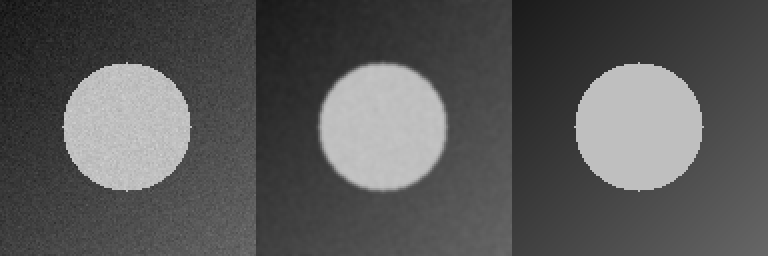

In [0]:
a4_2,b4_2,ref4_2=pair4(x4,clean_scene4,2)
z4_2=variant_summary4(2)
showmd4("**"*OPNAMES4[2]*"**\n\n"*summarytable4(z4_2))
println("ΔPSNR=",z4_2.rows[1][5]," дБ; операция ",class4(z4_2.rows[1][5]))
saveimage4("op2_result_seed101",a4_2)
saveimage4("op2_base_seed101",b4_2)
saveimage4("op2_reference",ref4_2)
display(Gray{N0f8}.(repeat(hcat(b4_2,a4_2,ref4_2),inner=(2,2))))

### Операция 3

Основной вариант. Гаусс σ=3 сильнее подавляет шум, но сильнее размывает границу диска.

**Гаусс σ=3**

| Метрика | База | s | После | Δ | Модуль Δ / s | >2s |
| --- | --- | --- | --- | --- | --- | --- |
| psnr | 33.98210314 | 0.07450306 | 26.86938720 | -7.11271593 | 95.469 | Да |
| edge | 0.01692549 | 0.00012750 | 0.00736260 | -0.00956289 | 75.002 | Да |
| contrast | 0.20774642 | 0.00017157 | 0.19481268 | -0.01293374 | 75.386 | Да |

ΔPSNR=-7.112715934118768 дБ; операция вредна


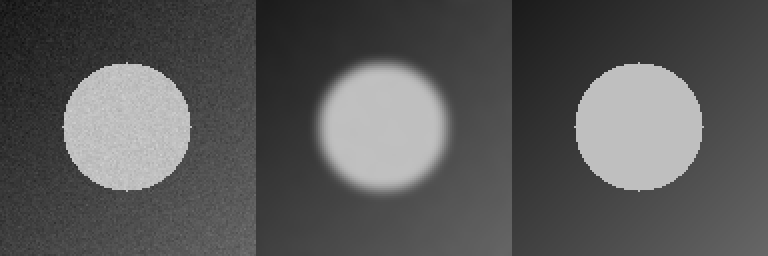

In [0]:
a4_3,b4_3,ref4_3=pair4(x4,clean_scene4,3)
z4_3=variant_summary4(3)
showmd4("**"*OPNAMES4[3]*"**\n\n"*summarytable4(z4_3))
println("ΔPSNR=",z4_3.rows[1][5]," дБ; операция ",class4(z4_3.rows[1][5]))
saveimage4("op3_result_seed101",a4_3)
saveimage4("op3_base_seed101",b4_3)
saveimage4("op3_reference",ref4_3)
display(Gray{N0f8}.(repeat(hcat(b4_3,a4_3,ref4_3),inner=(2,2))))

### Операция 4

Нерезкая маска x+(x−G₁*x) усиливает высокие частоты, в том числе шум; значения ограничиваются [0,1].

**Нерезкая маска**

| Метрика | База | s | После | Δ | Модуль Δ / s | >2s |
| --- | --- | --- | --- | --- | --- | --- |
| psnr | 33.98210314 | 0.07450306 | 26.98737941 | -6.99472373 | 93.885 | Да |
| edge | 0.01692549 | 0.00012750 | 0.02768047 | +0.01075498 | 84.352 | Да |
| contrast | 0.20774642 | 0.00017157 | 0.21695842 | +0.00921200 | 53.694 | Да |

ΔPSNR=-6.994723729299704 дБ; операция вредна


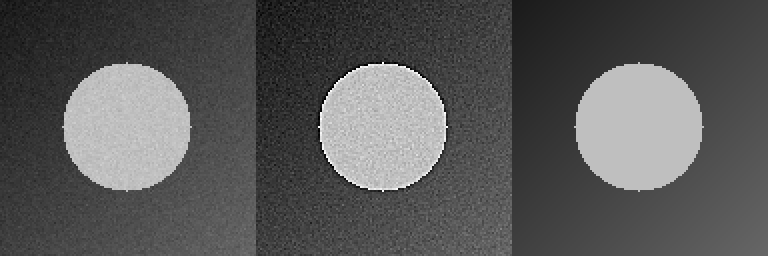

In [0]:
a4_4,b4_4,ref4_4=pair4(x4,clean_scene4,4)
z4_4=variant_summary4(4)
showmd4("**"*OPNAMES4[4]*"**\n\n"*summarytable4(z4_4))
println("ΔPSNR=",z4_4.rows[1][5]," дБ; операция ",class4(z4_4.rows[1][5]))
saveimage4("op4_result_seed101",a4_4)
saveimage4("op4_base_seed101",b4_4)
saveimage4("op4_reference",ref4_4)
display(Gray{N0f8}.(repeat(hcat(b4_4,a4_4,ref4_4),inner=(2,2))))

### Операция 5

Сначала Гаусс σ=1, затем Собель. Все карты делятся на один максимум градиента чистой сцены, затем ограничиваются [0,1].

**Собель после Гаусса**

| Метрика | База | s | После | Δ | Модуль Δ / s | >2s |
| --- | --- | --- | --- | --- | --- | --- |
| psnr | 28.86190838 | 0.11922173 | 25.27319018 | -3.58871820 | 30.101 | Да |
| edge | 0.02732162 | 0.00009124 | 0.01569778 | -0.01162385 | 127.397 | Да |
| contrast | 0.11659367 | 0.00038150 | 0.08458250 | -0.03201117 | 83.908 | Да |

ΔPSNR=-3.5887181980060667 дБ; операция вредна


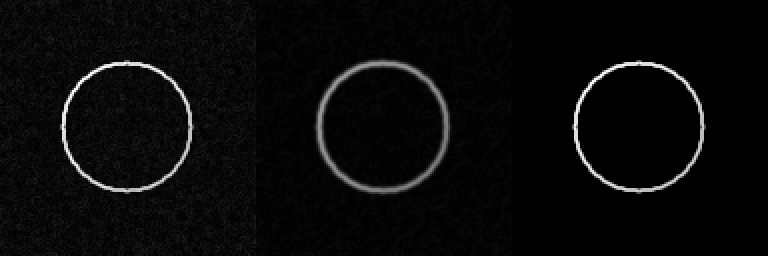

In [0]:
a4_5,b4_5,ref4_5=pair4(x4,clean_scene4,5)
z4_5=variant_summary4(5)
showmd4("**"*OPNAMES4[5]*"**\n\n"*summarytable4(z4_5))
println("ΔPSNR=",z4_5.rows[1][5]," дБ; операция ",class4(z4_5.rows[1][5]))
saveimage4("op5_result_seed101",a4_5)
saveimage4("op5_base_seed101",b4_5)
saveimage4("op5_reference",ref4_5)
display(Gray{N0f8}.(repeat(hcat(b4_5,a4_5,ref4_5),inner=(2,2))))

### Операция 6

Автоматический порог Оцу даёт маску; эрозия и следующая за ней дилатация удаляют мелкие включения. Эталон — истинный круг, дополнительно измеряем IoU.

**Оцу и открытие**

| Метрика | База | s | После | Δ | Модуль Δ / s | >2s |
| --- | --- | --- | --- | --- | --- | --- |
| psnr | 41.18995688 | 2.13375112 | 36.12359948 | -5.06635740 | 2.374 | Да |
| edge | 0.01267377 | 0.00008227 | 0.01246975 | -0.00020402 | 2.480 | Да |
| contrast | 0.39694023 | 0.00004181 | 0.39668754 | -0.00025269 | 6.044 | Да |

ΔPSNR=-5.0663574038403 дБ; операция вредна


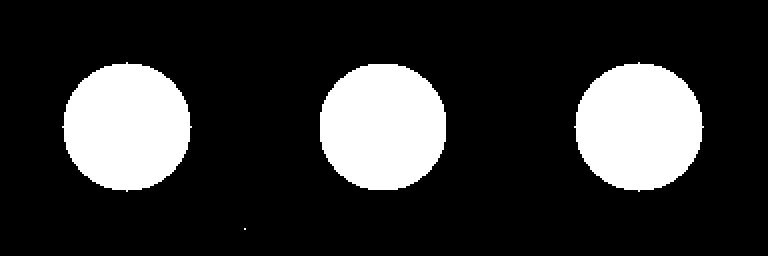

Средний IoU после открытия=0.9987535057650359


In [0]:
a4_6,b4_6,ref4_6=pair4(x4,clean_scene4,6)
z4_6=variant_summary4(6)
showmd4("**"*OPNAMES4[6]*"**\n\n"*summarytable4(z4_6))
println("ΔPSNR=",z4_6.rows[1][5]," дБ; операция ",class4(z4_6.rows[1][5]))
saveimage4("op6_result_seed101",a4_6)
saveimage4("op6_base_seed101",b4_6)
saveimage4("op6_reference",ref4_6)
display(Gray{N0f8}.(repeat(hcat(b4_6,a4_6,ref4_6),inner=(2,2))))
println("Средний IoU после открытия=",z4_6.iou)

## 6 Основной вариант 3 и соседняя сцена

Сохраняем результаты отдельно для каждого seed. Сравниваем Гаусс σ=1 и σ=3 на слабом шуме и σ=3 на соседней сцене с шумом 0.05. Дополнительная сцена меняет уровень шума при той же структуре; она показывает границы переноса вывода, но не представляет выборку реальных фотографий.

| Вариант | Шум | σ фильтра | PSNR до | PSNR после | Δ дБ | Класс |
| --- | --- | --- | --- | --- | --- | --- |
| 2 | 0.02 | 1 | 33.982103137714965 | 31.5887137620817 | -2.393389375633266 | вредна |
| 3 | 0.02 | 3 | 33.982103137714965 | 26.869387203596197 | -7.112715934118768 | вредна |
| 9 | 0.05 | 3 | 26.0253436915665 | 26.82010306264233 | 0.794759371075827 | нейтральна |

| Seed | PSNR до | PSNR после | MSE до | MSE после |
| --- | --- | --- | --- | --- |
| 101 | 33.92416352175621 | 26.878297279451267 | 0.00040511996625338124 | 0.0020519665272301073 |
| 102 | 33.92048070374465 | 26.860212862754565 | 0.00040546365376279884 | 0.00206052891714214 |
| 103 | 33.981572561203635 | 26.888474614772285 | 0.0003997999577434115 | 0.0020471635417118952 |
| 104 | 34.10474776248518 | 26.8566707348751 | 0.0003886200682880605 | 0.002062210180535601 |
| 105 | 33.97955113938513 | 26.863280526127788 | 0.00039998608777737826 | 0.0020590739649294478 |

Крупный фрагмент границы диска: база, Гаусс σ=3, чистый эталон.

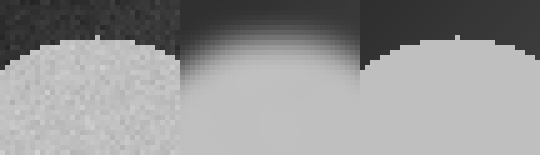

In [0]:
selected4=[variant_summary4(n) for n in (2,3,9)]
rows_selected4=[(z.variant,scene4(z.ctx).noise,z.fac==2 ? 1 : 3,z.rows[1][2],z.rows[1][4],z.rows[1][5],class4(z.rows[1][5])) for z in selected4]
showmd4(mdtable4(["Вариант","Шум","σ фильтра","PSNR до","PSNR после","Δ дБ","Класс"],rows_selected4))
main_series4=perseed4(1,3)
showmd4(mdtable4(["Seed","PSNR до","PSNR после","MSE до","MSE после"],[(r.seed,r.psnr_before,r.psnr_after,r.mse_before,r.mse_after) for r in main_series4]))
savedata4("gauss3_seed101",a4_3)
showmd4("Крупный фрагмент границы диска: база, Гаусс σ=3, чистый эталон.")
display(Gray{N0f8}.(repeat(hcat(x4[25:55,45:80],a4_3[25:55,45:80],clean_scene4[25:55,45:80]),inner=(5,5))))
neighbor4=make_gray4(101;scene4(2)...)
saveimage4("neighbor_noisy_seed101",neighbor4)
saveimage4("neighbor_gauss3_seed101",gauss4(neighbor4,3))

## 7 Обзор сочетаний и сохранение таблиц

Для полноты выполняем `variant_summary4` для всех 30 сочетаний. Это описательный обзор; основной вывод и гипотеза относятся к варианту 3. Сохраняем метрики каждого seed и сводки, чтобы проверка не зависела от округлений в ноутбуке. `NaN` в IoU для операций 1–5 означает «не применимо».

In [0]:
all_summary4=[variant_summary4(n) for n in 1:30]
all_perseed4=[r for c in 1:5 for k in 1:6 for r in perseed4(c,k)]
headers4=collect(keys(first(all_perseed4)))
csv4("per_seed.csv",headers4,[Tuple(r) for r in all_perseed4])
summary_rows4=[(z.variant,z.ctx,z.fac,row...,z.iou) for z in all_summary4 for row in z.rows]
csv4("summary.csv",["variant","scene","operation","metric","base","s","after","delta","ratio","stat_significant","iou_after"],summary_rows4)
showmd4(mdtable4(["Вариант","Операция","PSNR до","PSNR после","Δ дБ","Класс"],[(z.variant,OPNAMES4[z.fac],@sprintf("%.3f",z.rows[1][2]),@sprintf("%.3f",z.rows[1][4]),@sprintf("%+.3f",z.rows[1][5]),class4(z.rows[1][5])) for z in all_summary4]))

| Вариант | Операция | PSNR до | PSNR после | Δ дБ | Класс |
| --- | --- | --- | --- | --- | --- |
| 1 | Усреднение 5×5 | 33.982 | 29.196 | -4.786 | вредна |
| 2 | Гаусс σ=1 | 33.982 | 31.589 | -2.393 | вредна |
| 3 | Гаусс σ=3 | 33.982 | 26.869 | -7.113 | вредна |
| 4 | Нерезкая маска | 33.982 | 26.987 | -6.995 | вредна |
| 5 | Собель после Гаусса | 28.862 | 25.273 | -3.589 | вредна |
| 6 | Оцу и открытие | 41.190 | 36.124 | -5.066 | вредна |
| 7 | Усреднение 5×5 | 26.025 | 28.891 | +2.866 | полезна |
| 8 | Гаусс σ=1 | 26.025 | 30.570 | +4.545 | полезна |
| 9 | Гаусс σ=3 | 26.025 | 26.820 | +0.795 | нейтральна |
| 10 | Нерезкая маска | 26.025 | 20.519 | -5.507 | вредна |
| 11 | Собель после Гаусса | 20.458 | 24.222 | +3.764 | полезна |
| 12 | Оцу и открытие | 33.009 | 36.124 | +3.115 | полезна |
| 13 | Усреднение 5×5 | 20.121 | 27.953 | +7.832 | полезна |
| 14 | Гаусс σ=1 | 20.121 | 28.202 | +8.081 | полезна |
| 15 | Гаусс σ=3 | 20.121 | 26.641 | +6.520 | полезна |
| 16 | Нерезкая маска | 20.121 | 15.404 | -4.717 | вредна |
| 17 | Собель после Гаусса | 14.404 | 21.648 | +7.244 | полезна |
| 18 | Оцу и открытие | 16.880 | 29.338 | +12.458 | полезна |
| 19 | Усреднение 5×5 | 26.024 | 27.464 | +1.439 | полезна |
| 20 | Гаусс σ=1 | 26.024 | 29.535 | +3.511 | полезна |
| 21 | Гаусс σ=3 | 26.024 | 25.332 | -0.692 | нейтральна |
| 22 | Нерезкая маска | 26.024 | 20.362 | -5.662 | вредна |
| 23 | Собель после Гаусса | 21.176 | 23.252 | +2.076 | полезна |
| 24 | Оцу и открытие | 20.901 | 36.124 | +15.222 | полезна |
| 25 | Усреднение 5×5 | 30.460 | 39.442 | +8.981 | полезна |
| 26 | Гаусс σ=1 | 30.460 | 39.184 | +8.723 | полезна |
| 27 | Гаусс σ=3 | 30.460 | 38.513 | +8.053 | полезна |
| 28 | Нерезкая маска | 30.460 | 25.069 | -5.391 | вредна |
| 29 | Собель после Гаусса | 13.615 | 21.561 | +7.946 | полезна |
| 30 | Оцу и открытие | 8.288 | 17.909 | +9.621 | полезна |

## 8 Вывод и ограничения

Вывод ниже формируется по фактическому результату выполнения. Учебный критерий `2s` оценивает отношение сдвига к разбросу базовой метрики, а практический критерий оценивает пользу по PSNR относительно эталона. Рост энергии границ может означать усиление шума; её снижение — как подавление шума, так и размытие полезного контура. PSNR не заменяет визуальный осмотр.

In [0]:
zmain4=all_summary4[3]
dmain4=zmain4.rows[1][5]
fmt4(x)=@sprintf("%.4f",x)
hypothesis_result4=dmain4<0 ? "подтверждена" : "не подтверждена"
conclusion4="## Вывод по варианту 3\n\n"*
"Средний PSNR: $(fmt4(zmain4.rows[1][2])) → $(fmt4(zmain4.rows[1][4])) дБ; Δ=$(fmt4(dmain4)) дБ. По заранее записанному допуску ±1 дБ операция **$(class4(dmain4))** для данной сцены.\n\n"*
"Гипотеза о снижении PSNR $hypothesis_result4. Энергия границ: $(zmain4.rows[2][2]) → $(zmain4.rows[2][4]); контраст: $(zmain4.rows[3][2]) → $(zmain4.rows[3][4]).\n\n"*
"При порогах 0.5, 1 и 2 дБ классификации: $(class4(dmain4,0.5)), $(class4(dmain4,1.0)), $(class4(dmain4,2.0)). Соседняя сцена 2: ΔPSNR=$(all_summary4[9].rows[1][5]) дБ, $(class4(all_summary4[9].rows[1][5])).\n\n"*
"Вывод ограничен синтетической сценой 128×128, пятью реализациями шума, выбранными параметрами фильтра и продолжением крайних значений. Seed не создаёт новую геометрию сцены. Для переноса вывода нужны разные реальные сцены и известные эталоны; на следующих экспериментах полезны больший набор seed и дополнительные метрики структуры."
showmd4(conclusion4)
write(joinpath(LR04_OUT,"conclusion.md"),conclusion4)

## Вывод по варианту 3

Средний PSNR: 33.9821 → 26.8694 дБ; Δ=-7.1127 дБ. По заранее записанному допуску ±1 дБ операция **вредна** для данной сцены.

Гипотеза о снижении PSNR подтверждена. Энергия границ: 0.01692548814288977 → 0.0073626014145217345; контраст: 0.20774642267754806 → 0.19481267789727424.

При порогах 0.5, 1 и 2 дБ классификации: вредна, вредна, вредна. Соседняя сцена 2: ΔPSNR=0.794759371075827 дБ, нейтральна.

Вывод ограничен синтетической сценой 128×128, пятью реализациями шума, выбранными параметрами фильтра и продолжением крайних значений. Seed не создаёт новую геометрию сцены. Для переноса вывода нужны разные реальные сцены и известные эталоны; на следующих экспериментах полезны больший набор seed и дополнительные метрики структуры.

1242

## 9 Контрольные вопросы

1. При σₙ=0.05 оценка PSNR равна −20log10(0.05)=26.02 дБ; при 0.10 — 20 дБ: удвоение шума уменьшает PSNR примерно на 6.02 дБ.
2. Гаусс придаёт ближайшим пикселям больший вес. Рост σ расширяет сглаживание и размывает границы; сравнение с усреднением зависит от размеров ядер.
3. Ошибка после сглаживания включает остаточный шум и искажение деталей. При слабом шуме потери на границах могут превысить выигрыш, при сильном — наоборот.
4. Эталон Собеля получают из чистой сцены. Карты сравнивают при одной нормировке на максимум чистого градиента; отдельная нормировка каждой карты скрыла бы различие амплитуд.
5. Предварительное сглаживание подавляет ложные шумовые границы, но может ослабить настоящие; энергия границ обычно снижается.
6. Открытие — эрозия, затем дилатация; удаляет мелкие выступы и включения. Закрытие — дилатация, затем эрозия; заполняет мелкие отверстия и разрывы. Результат зависит от структурного элемента.
7. Объединение содержит 3000+3200−2900=3300 пикселей; IoU=2900/3300≈0.8788.
8. При фиксированной геометрии меняется лишь шум, а метрики усредняют много пикселей: s мал. Поэтому критерий 2s часто срабатывает и не показывает пользу операции.
9. Увеличить число seed, проверить несколько сцен и уровней шума, заранее обосновать допуск, использовать PSNR совместно с визуальной оценкой и метриками структуры. Один рост числа seed не устраняет ограничение одной сцены.
10. Записать среду, версии языка и библиотек, хеши исходников, размер, параметры сцены, seed, эталон, параметры операции, обработку краёв, структурный элемент, метрики и практический допуск.

## 10 Паспорт и артефакты

Ниже сохраняются фактические версии, хеши, параметры и таблицы. Источники: предоставленные методичка и библиотеки; [документация WorkspaceArray](https://engee.com/helpcenter/stable/ru/guide/workspacearray.html); собственные результаты запуска. Метрики считаются по Float64; файлы `.f64` записаны little-endian по столбцам Julia, PNG квантованы до 8 бит только для просмотра. Библиотеки преподавателя не изменяются.

In [0]:
@assert length(all_perseed4)==150
@assert length(all_summary4)==30
@assert all(all(isfinite,row[2:6]) for z in all_summary4 for row in z.rows)
@assert DEMO_MATCH4
@assert isapprox(mean(r.psnr_after for r in main_series4),zmain4.rows[1][4];atol=1e-10)
passport4=Dict("Engee"=>"26.9.2-H4","status"=>"executed","date"=>string(now()),"started_at"=>LR04_STARTED,"student"=>"Власюк Данил Витальевич","group"=>"Т26ИИКТ-МИК11","variant"=>3,"julia"=>string(VERSION),"platform"=>string(Sys.MACHINE),"Images"=>string(pkgversion(Images)),"seeds"=>collect(SEEDS4),"size"=>[128,128],"noise"=>0.02,"bg"=>[0.1,0.4],"disc"=>0.75,"checker"=>0,"gaussian_sigma"=>3,"border"=>"replicate","practical_threshold_db"=>1.0,"scene_sha256"=>SHA_SCENE4,"demo_match"=>DEMO_MATCH4,"library03_sha256"=>bytes2hex(sha256(read("lab03_lib.jl"))),"library04_sha256"=>bytes2hex(sha256(read("lab04_lib.jl"))),"hypothesis_sha256"=>bytes2hex(sha256(read("hypothesis.md"))),"float64_order"=>"Julia column-major little-endian","main_delta_psnr"=>dmain4,"main_class"=>class4(dmain4))
open(joinpath(LR04_OUT,"passport.toml"),"w") do io;TOML.print(io,passport4);end
open(joinpath(LR04_OUT,"versioninfo.txt"),"w") do io;versioninfo(io);end
passport_md4="# Паспорт эксперимента ЛР4 вариант 3\n\n"*join(["- **$k:** $v" for (k,v) in sort(collect(passport4);by=first)],"\n")
write(joinpath(LR04_OUT,"passport.md"),passport_md4)
showmd4(passport_md4)
Tar.create(LR04_OUT,joinpath(LR04_ROOT,"LR04_variant3_results.tar"))
println("ALL CHECKS PASS; COMPLETE ",now(),"; ARCHIVE ",joinpath(LR04_ROOT,"LR04_variant3_results.tar"))

# Паспорт эксперимента ЛР4 вариант 3

- **Engee:** 26.9.2-H4
- **Images:** 0.26.2
- **bg:** [0.1, 0.4]
- **border:** replicate
- **checker:** 0
- **date:** 2026-10-14T19:39:11.259
- **demo_match:** true
- **disc:** 0.75
- **float64_order:** Julia column-major little-endian
- **gaussian_sigma:** 3
- **group:** Т26ИИКТ-МИК11
- **hypothesis_sha256:** 8c2e3c351ff61b9daf01d93b5aa5bd1698ccf571961c19bfbdf375edd1e27c49
- **julia:** 1.12.4
- **library03_sha256:** cd1622643e7cfe7cc01bb7d8067e4802a76f6a76e9a6833ba4c09c84bb9fa62a
- **library04_sha256:** 094cecea2f55a0f53a652149a1a4025e98d87b3994b376be7028c4920cb0f8c2
- **main_class:** вредна
- **main_delta_psnr:** -7.112715934118768
- **noise:** 0.02
- **platform:** x86_64-linux-gnu
- **practical_threshold_db:** 1.0
- **scene_sha256:** e7ecd4f73ea684ab746fc444eef55f0c18943d7fdcfc4fe7866b3f4b6012accf
- **seeds:** [101, 102, 103, 104, 105]
- **size:** [128, 128]
- **started_at:** 2026-10-14T19:38:58.968
- **status:** executed
- **student:** Власюк Данил Витальевич
- **variant:** 3

ALL CHECKS PASS; COMPLETE 2026-10-14T19:39:11.499; ARCHIVE /user/AI_in_creative_media/LR04/LR04_variant3_results.tar
